# 📊 EDA & Statistical Analysis (Unit 2)
Exploratory data analysis covering univariate, bivariate, and multivariate views.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Loaded: {df_clean.shape}")

Loaded: (1359, 12)


## Cell 5: Target Variable Analysis (Unit 2 - EDA)
Most wines are average quality (5-6); excellent wines (7-8) are rare.

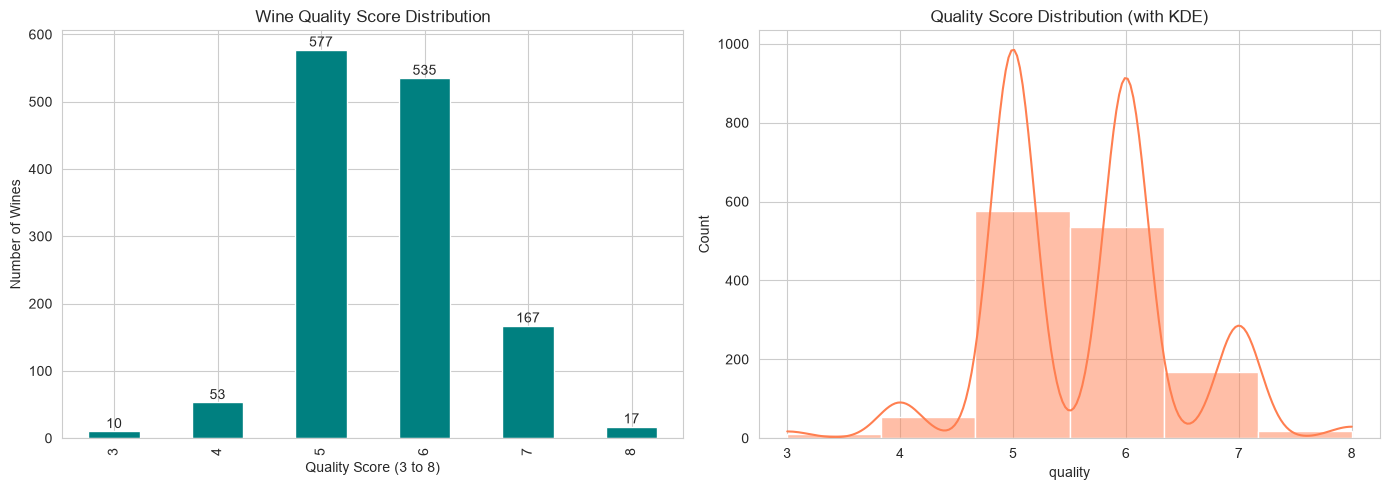

Mean quality: 5.62
Median quality: 6.00
Standard deviation: 0.82


In [2]:
# Unit 2: EDA - Univariate analysis of target variable

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot of quality scores
quality_counts = df_clean['quality'].value_counts().sort_index()
quality_counts.plot(kind='bar', ax=axes[0], color='teal')
axes[0].set_title('Wine Quality Score Distribution')
axes[0].set_xlabel('Quality Score (3 to 8)')
axes[0].set_ylabel('Number of Wines')

# Add counts on top of bars
for i, v in enumerate(quality_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center')

# Distribution plot
sns.histplot(df_clean['quality'], kde=True, ax=axes[1], bins=6, color='coral')
axes[1].set_title('Quality Score Distribution (with KDE)')

plt.tight_layout()
plt.show()

print(f"Mean quality: {df_clean['quality'].mean():.2f}")
print(f"Median quality: {df_clean['quality'].median():.2f}")
print(f"Standard deviation: {df_clean['quality'].std():.2f}")

## Cell 6: Univariate Analysis - Feature Distributions (Unit 2)

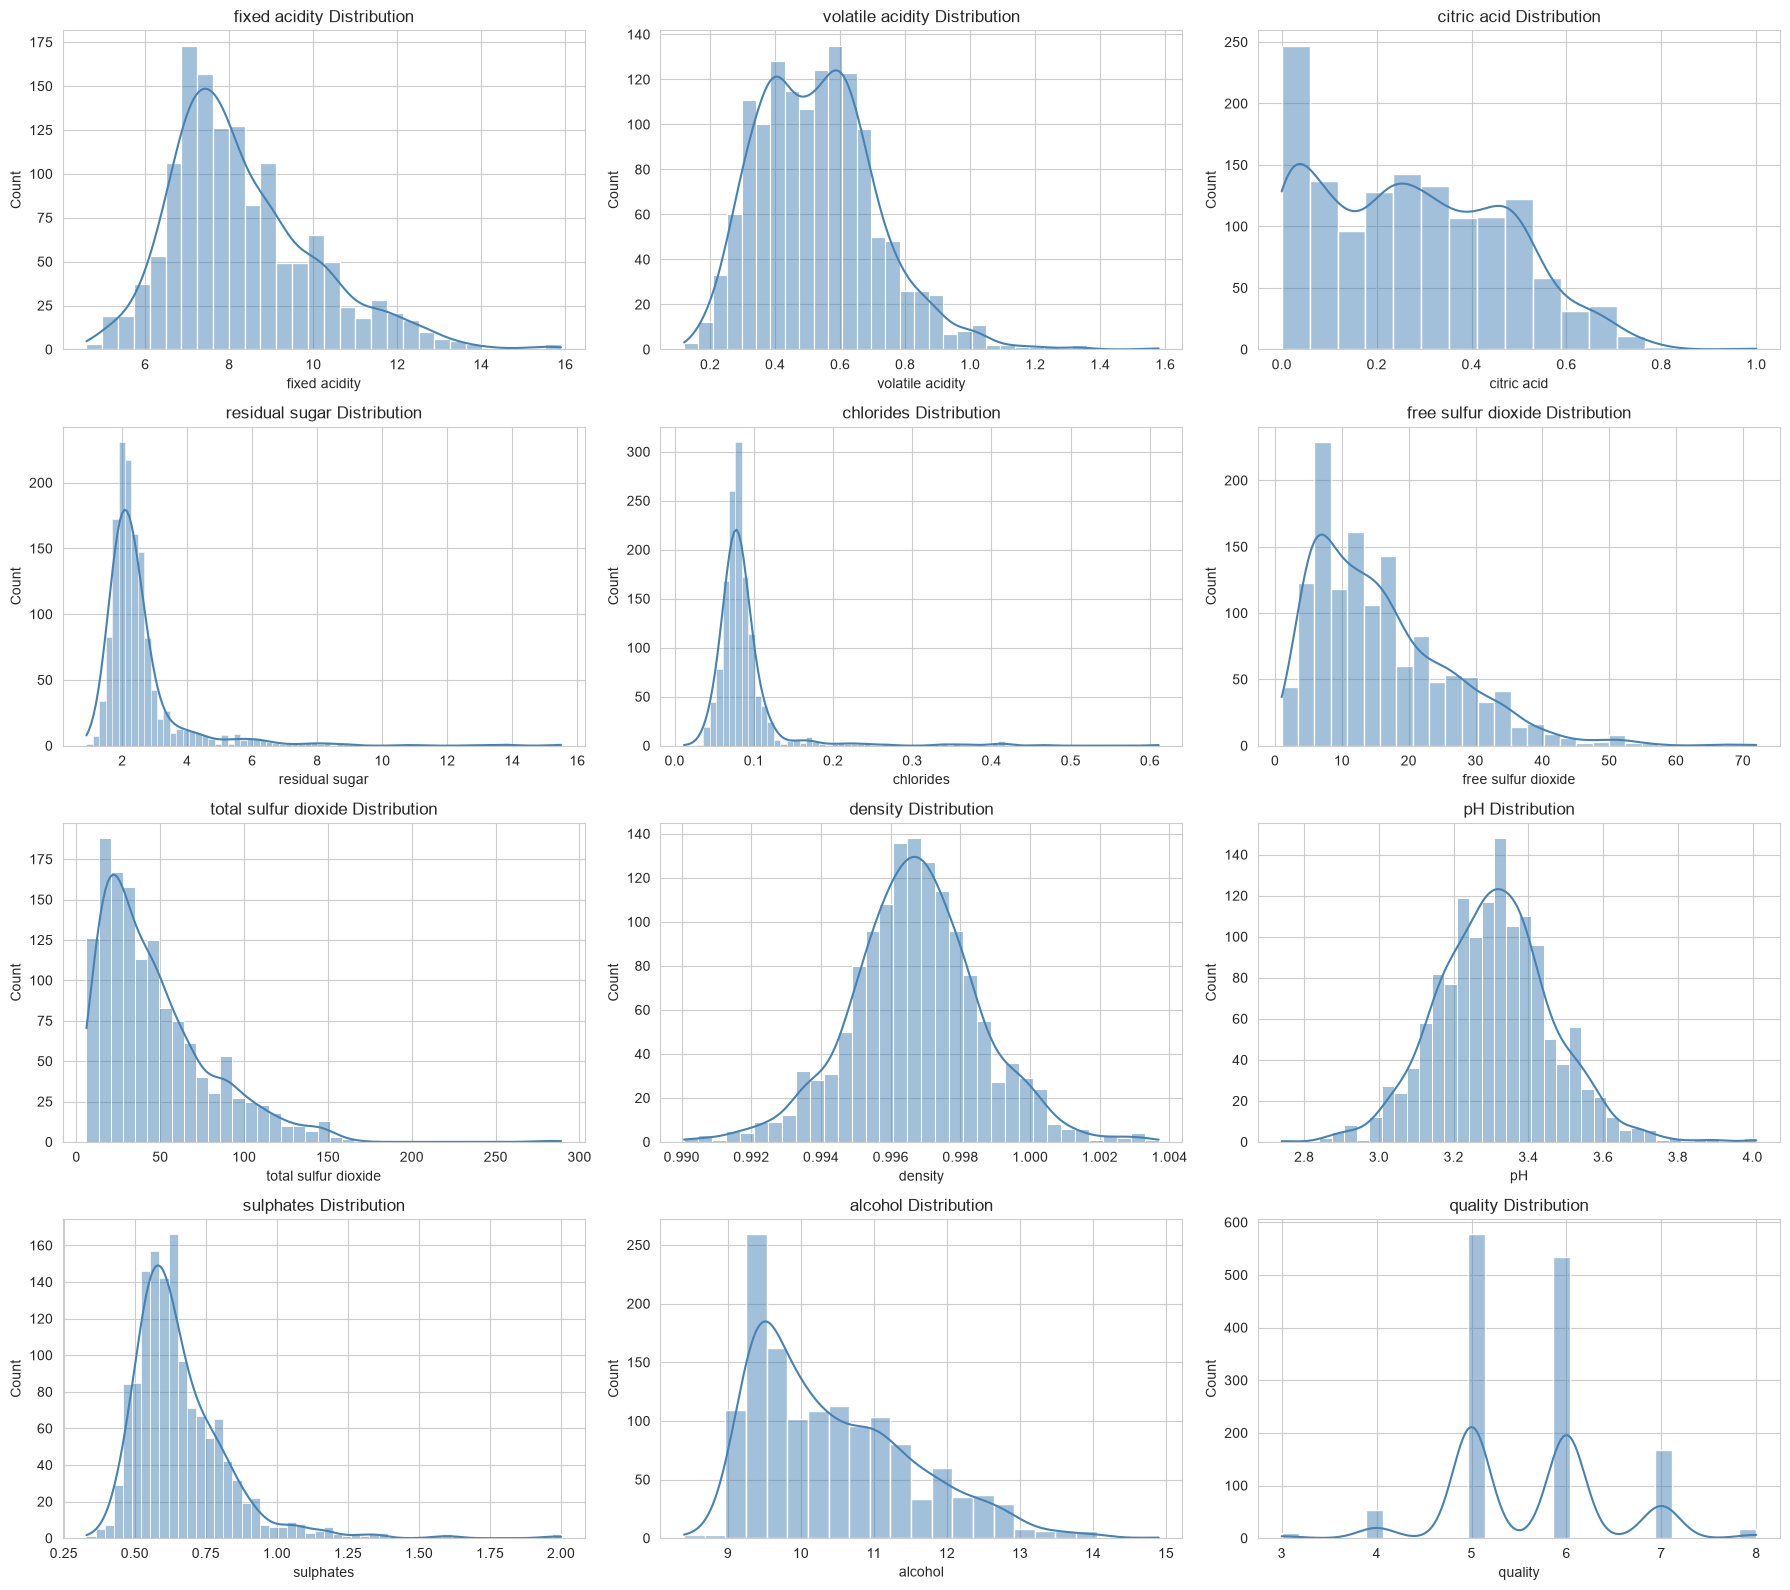

In [3]:
# Unit 2: Univariate analysis of all features

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
features = df_clean.columns.tolist()

for idx, col in enumerate(features):
    row, col_idx = idx // 3, idx % 3
    sns.histplot(df_clean[col], kde=True, ax=axes[row, col_idx], color='steelblue')
    axes[row, col_idx].set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()

## Cell 7: Outlier Detection - IQR Method (Unit 2)

Outlier Count per Feature (IQR Method):
             Feature  Outlier_Count
      residual sugar            126
           chlorides             87
           sulphates             55
total sulfur dioxide             45
       fixed acidity             41
             density             35
                  pH             28
             quality             27
 free sulfur dioxide             26
    volatile acidity             19
             alcohol             12
         citric acid              1


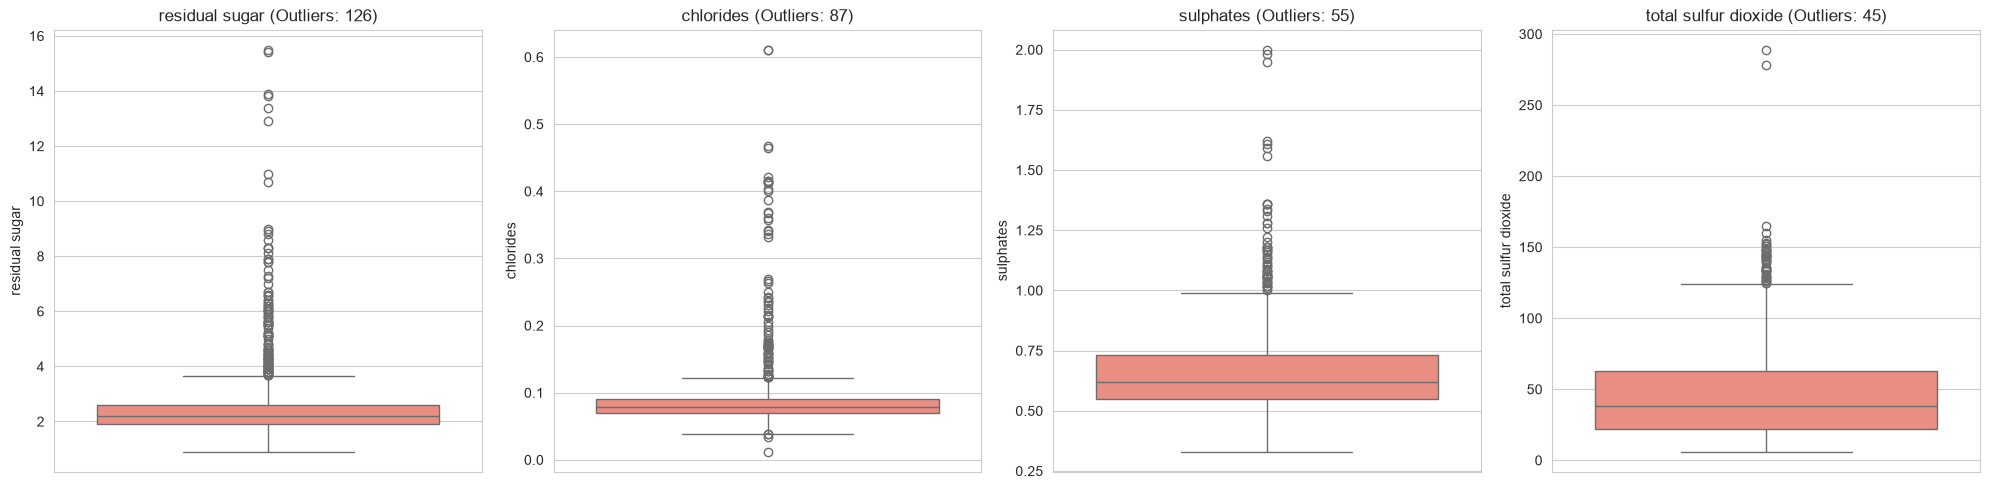


Note: We retain outliers since extreme values (e.g., very high alcohol)
can be genuinely good/bad wines. Removing them may lose real information.


In [4]:
# Unit 2: Outlier detection using IQR (Interquartile Range)

outlier_summary = {}
for col in df_clean.columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = df_clean[(df_clean[col] < lower) | (df_clean[col] > upper)].shape[0]
    outlier_summary[col] = count

outlier_df = pd.DataFrame(list(outlier_summary.items()), 
                          columns=['Feature', 'Outlier_Count'])
outlier_df = outlier_df.sort_values('Outlier_Count', ascending=False)

print("Outlier Count per Feature (IQR Method):")
print(outlier_df.to_string(index=False))

# Visualize outliers for top affected features
top_outlier_features = outlier_df.head(4)['Feature'].tolist()
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for idx, col in enumerate(top_outlier_features):
    sns.boxplot(y=df_clean[col], ax=axes[idx], color='salmon')
    axes[idx].set_title(f'{col} (Outliers: {outlier_summary[col]})')

plt.tight_layout()
plt.show()

print("\nNote: We retain outliers since extreme values (e.g., very high alcohol)")
print("can be genuinely good/bad wines. Removing them may lose real information.")

## Cell 8: Bivariate & Correlation Analysis (Unit 2)

Correlation with Wine Quality:
quality                 1.000
alcohol                 0.480
sulphates               0.249
citric acid             0.228
fixed acidity           0.119
residual sugar          0.014
free sulfur dioxide    -0.050
pH                     -0.055
chlorides              -0.131
total sulfur dioxide   -0.178
density                -0.184
volatile acidity       -0.395
Name: quality, dtype: float64


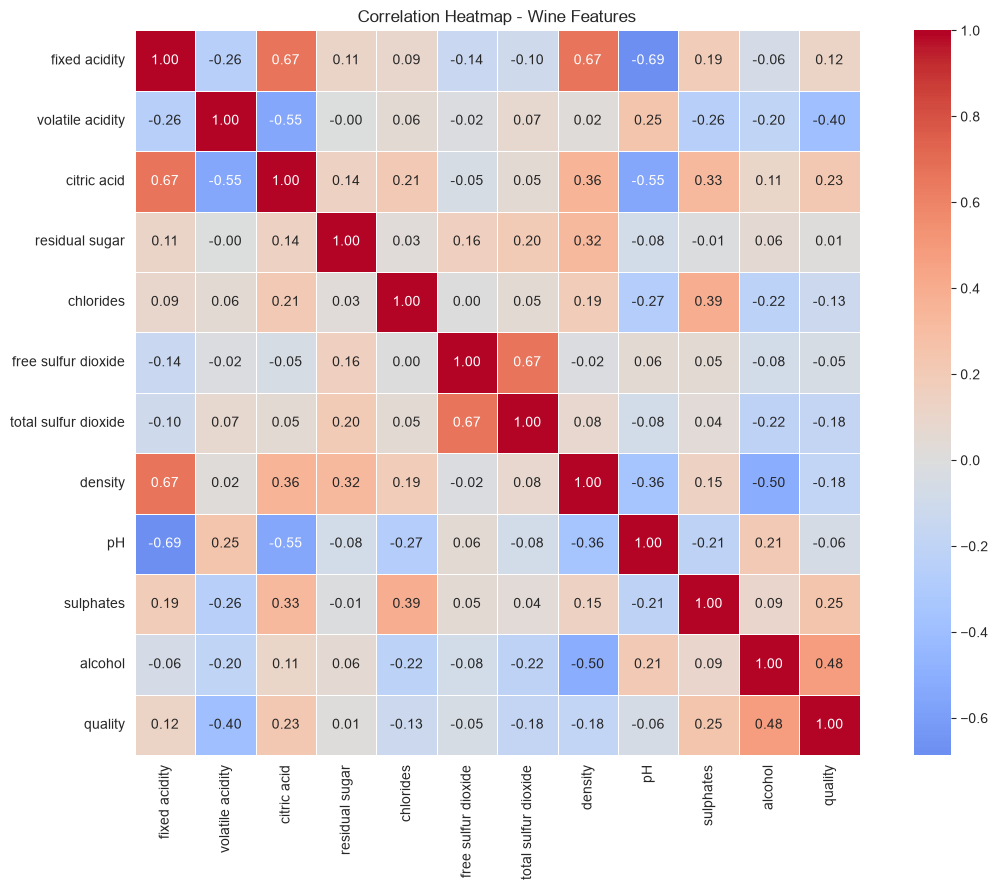

In [5]:
# Unit 2: Correlation analysis

correlation_matrix = df_clean.corr()

# Correlation of all features with target
target_corr = correlation_matrix['quality'].sort_values(ascending=False)
print("Correlation with Wine Quality:")
print(target_corr.round(3))

# Heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap - Wine Features')
plt.tight_layout()
plt.show()

## Cell 9: Key Relationships Visualization (Unit 2)
Alcohol shows the strongest positive correlation; volatile acidity the strongest negative.

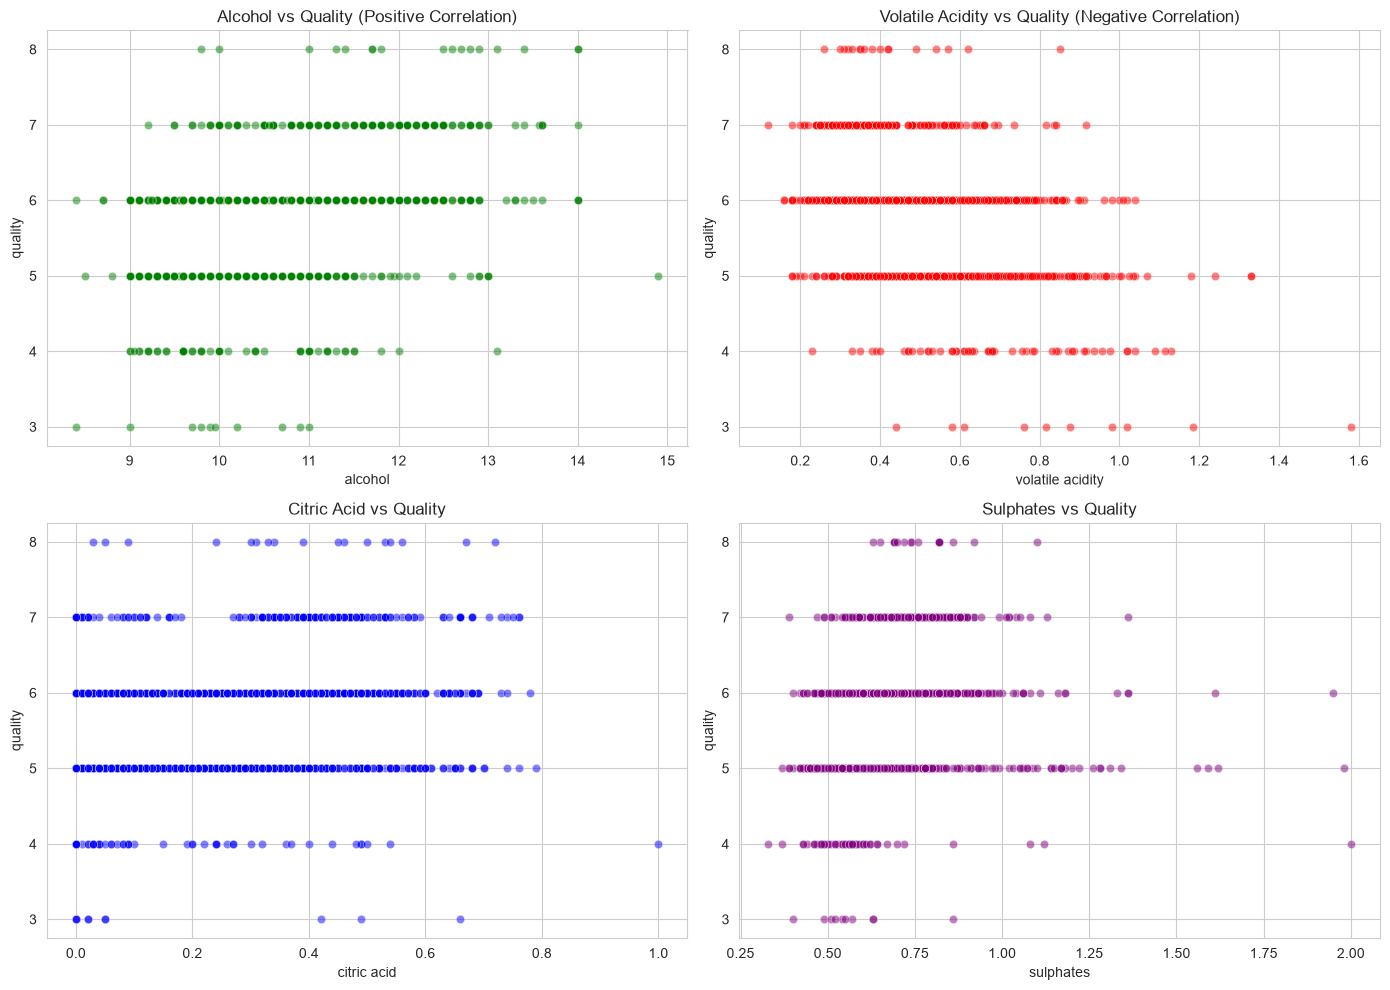

In [6]:
# Unit 2: Bivariate analysis - strongest positive & negative correlations

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Alcohol vs Quality (strongest positive)
sns.scatterplot(x='alcohol', y='quality', data=df_clean, ax=axes[0,0], alpha=0.5, color='green')
axes[0,0].set_title('Alcohol vs Quality (Positive Correlation)')

# Volatile Acidity vs Quality (strongest negative)
sns.scatterplot(x='volatile acidity', y='quality', data=df_clean, ax=axes[0,1], alpha=0.5, color='red')
axes[0,1].set_title('Volatile Acidity vs Quality (Negative Correlation)')

# Citric Acid vs Quality
sns.scatterplot(x='citric acid', y='quality', data=df_clean, ax=axes[1,0], alpha=0.5, color='blue')
axes[1,0].set_title('Citric Acid vs Quality')

# Sulphates vs Quality
sns.scatterplot(x='sulphates', y='quality', data=df_clean, ax=axes[1,1], alpha=0.5, color='purple')
axes[1,1].set_title('Sulphates vs Quality')

plt.tight_layout()
plt.show()

## Cell 10: Multivariate Analysis (Unit 2)

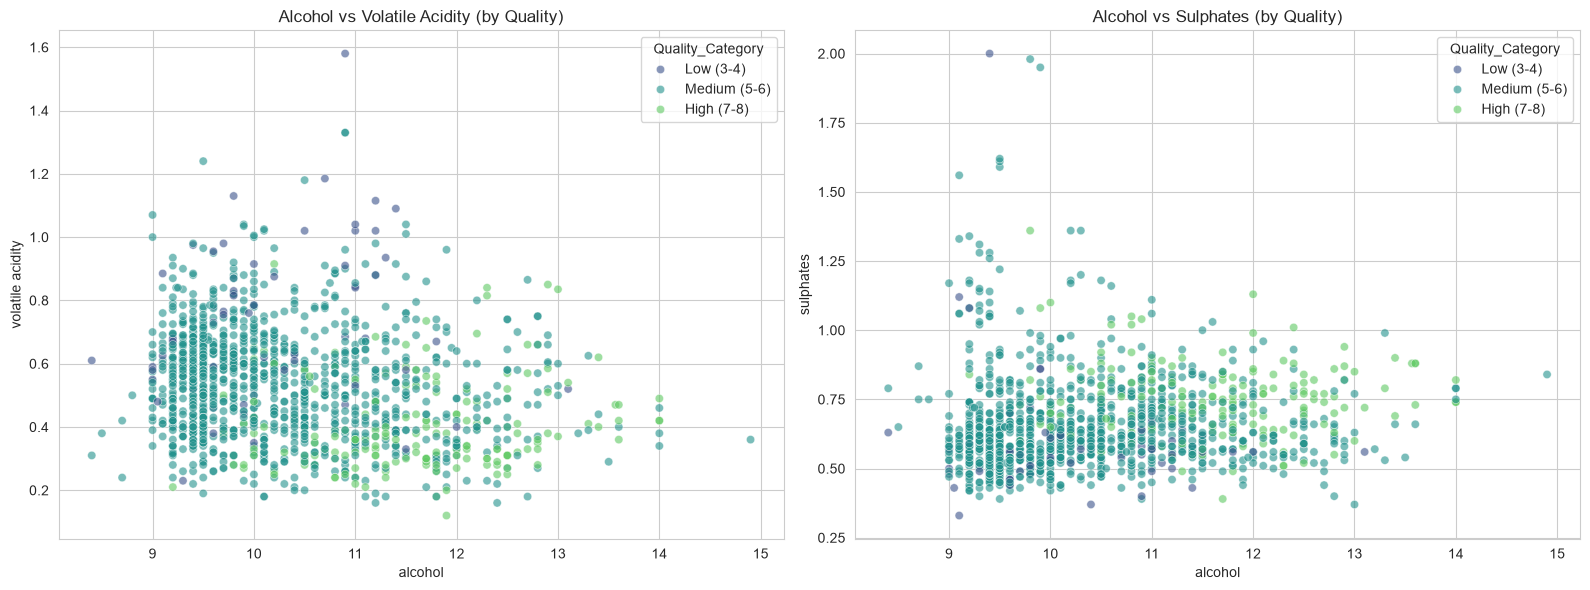

In [7]:
# Unit 2: Multivariate analysis - feature pairs colored by quality category

# Create quality categories for visualization
df_viz = df_clean.copy()
df_viz['Quality_Category'] = pd.cut(df_viz['quality'], 
                                     bins=[2, 4, 6, 8], 
                                     labels=['Low (3-4)', 'Medium (5-6)', 'High (7-8)'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Alcohol vs Volatile Acidity
sns.scatterplot(x='alcohol', y='volatile acidity', hue='Quality_Category', 
                data=df_viz, ax=axes[0], palette='viridis', alpha=0.6)
axes[0].set_title('Alcohol vs Volatile Acidity (by Quality)')

# Alcohol vs Sulphates
sns.scatterplot(x='alcohol', y='sulphates', hue='Quality_Category', 
                data=df_viz, ax=axes[1], palette='viridis', alpha=0.6)
axes[1].set_title('Alcohol vs Sulphates (by Quality)')

plt.tight_layout()
plt.show()